# Beyond Uniform Downsampling
## Boundary-Aware Visual Token Compression for Geospatial Pixel Reasoning: live demo

**Team:** Animesh Kumar (230907478) · Preyanshi Doshi (230907042)  |  **Mentor:** Dr. Aarabhi Putty  |  MIT Manipal

SegEarth-R1 squeezes 1024 image features into **64 tokens**, one per patch, before its language model reads them. We proposed **BAC**, which spends those tokens on object boundaries instead. This notebook shows, live, what we found:

| § | what you will see | time |
|---|---|---|
| 1–2 | the drop-in tests, then loading the real model | ~1 min |
| 3 | released model vs BAC on hard cases: the same masks | ~2 min |
| 3b–3c | delete or swap the image tokens: nothing changes (the masks ignore them) | ~1 min |
| 4 | all numbers inside SegEarth-R1: every compressor ties | instant |
| 5 | the fair test, where tokens matter: BAC trained with true outlines wins | instant |
| 6 | the real weakness (unseen object types) and our fix, live | ~1 min |
| 7–8 | checked on a second computer; try your own question | — |

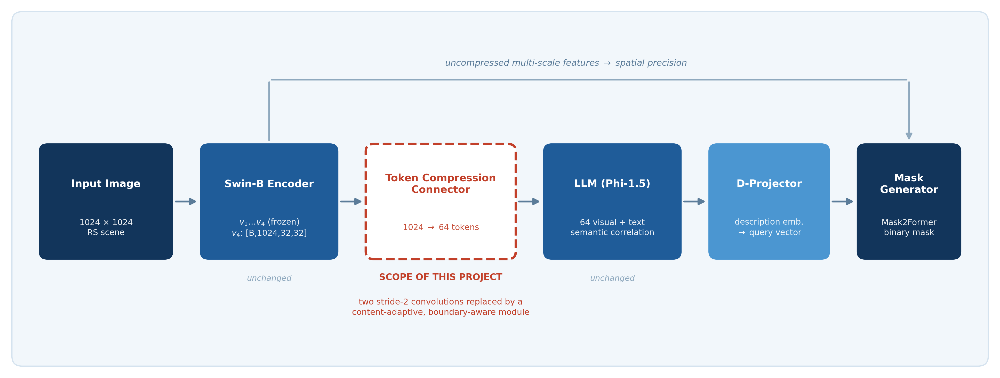

In [ ]:
import os, sys, json, warnings, logging
warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'                                  # no fork warning from shell cells
logging.getLogger('torch.distributed.elastic.multiprocessing.redirects').setLevel(logging.ERROR)
ROOT = os.path.abspath('.')
sys.path.insert(0, os.path.join(ROOT, 'bac'))
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
import transformers; transformers.logging.set_verbosity_error()
from IPython.display import Image, display
from demo_utils import *
plt.rcParams['figure.dpi'] = 110
display(Image(os.path.join(ROOT, 'files', 'fig1_pipeline.png'), width=900))

## 1. The drop-in tests
Every compressor gives exactly the output shape the language model expects, at every budget; the score layer of BAC really receives a learning signal.

In [ ]:
!cd "{ROOT}" && .venv/bin/python bac/test_connectors.py 2>&1 | grep -v -i "warn\|redirect\|pytree"

kind        M          out shape     params      ms
uniform    16      (2, 16, 2048)     99.95M    57.0
uniform    32      (2, 32, 2048)    100.02M    51.7
uniform    64      (2, 64, 2048)     62.13M    28.2
uniform   128     (2, 128, 2048)     62.40M    35.9
pool       16      (2, 16, 2048)      2.10M     2.4
pool       32      (2, 32, 2048)      2.10M     0.8
pool       64      (2, 64, 2048)      2.10M     1.0
pool      128     (2, 128, 2048)      2.10M     1.5
random     16      (2, 16, 2048)      2.10M     2.8
random     32      (2, 32, 2048)      2.10M     1.0
random     64      (2, 64, 2048)      2.10M     1.1
random    128     (2, 128, 2048)      2.10M     1.9
tome       16      (2, 16, 2048)      2.10M     9.4
tome       32      (2, 32, 2048)      2.10M     7.6
tome       64      (2, 64, 2048)      2.10M     7.2
tome      128     (2, 128, 2048)      2.10M     7.4
bac        16      (2, 16, 2048)      2.10M     6.4
bac        32      (2, 32, 2048)      2.10M     2.3
bac        6

**A flaw we fixed.** Our proposal multiplied each kept token by its score and then normalised it. Normalising removes any scaling, so the score vanished and could not learn (its gradient was practically zero, about 15,000 times smaller). We normalise first and multiply by *score ÷ a frozen copy of the score*: the value is unchanged, but the score now gets a learning signal (the test above checks this).

## 2. Load SegEarth-R1 (released EarthReason checkpoint) on this machine

In [ ]:
tok, model, device = load_model()
bank = ConnectorBank(model)
print('device:', device, '| connectors available:', bank.available())

loading segmentation model
current model is segearth_r1
Mask Decoder has been trained, init directly
current seg concat mode: False, seg_norm: False, seg_proj: True, seg_fuse_score: False
device: mps | connectors available: ['released', 'bac128', 'bac16', 'bac32', 'bac64', 'bac64_lam0', 'bac64_learned', 'bac64_nonms', 'bac64_nope', 'bac64_rho25', 'bac64_rho75', 'bac64_sobel', 'pool128', 'pool16', 'pool32', 'pool64', 'random64', 'tome64', 'uniform16', 'uniform64']


## 3. Live: released compressor vs BAC on hard cases
Small targets (helipad, wind turbine) and thin ones (runway, pier) are where a uniform compressor should lose information.

*Single images can differ by a few IoU points; averaged over 300 images every compressor is within about one gIoU point of the released model (§4).*

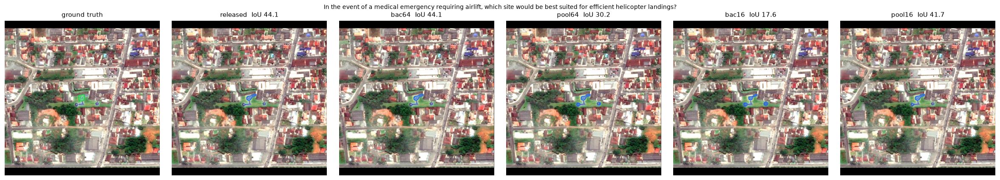

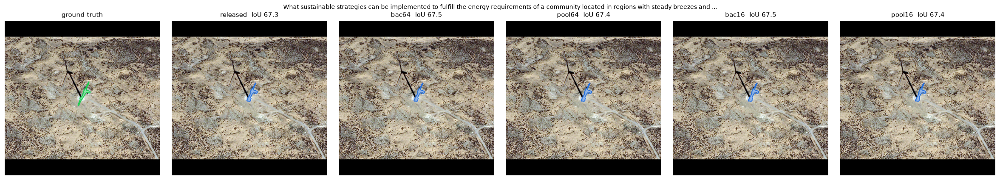

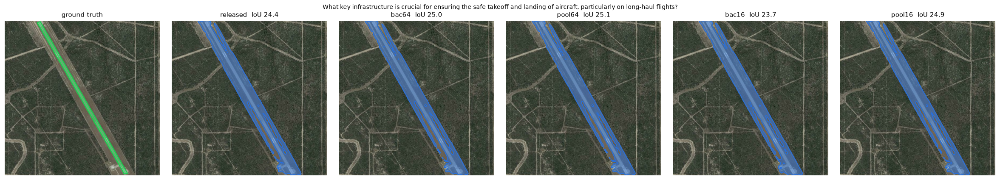

In [ ]:
EXAMPLES = ['0305', '5403', '0328', '2796', '4050', '0024']   # helipad, wind turbine, runway, pier, storage tank, empty target
COMPARE  = [c for c in ['released', 'bac64', 'pool64', 'bac16', 'pool16'] if c in bank.available()]

def show(name, connectors=COMPARE):
    img, gt, q, a = load_example(name)
    res = {}
    for c in connectors:
        bank.use(c)
        res[c] = run(model, tok, device, img, q, a, gt)
    fig = compare_figure(img, res[connectors[0]]['gt'], res, q)
    plt.show()
    return img, res

outs = {}
for ex in EXAMPLES[:3]:
    outs[ex] = show(ex)

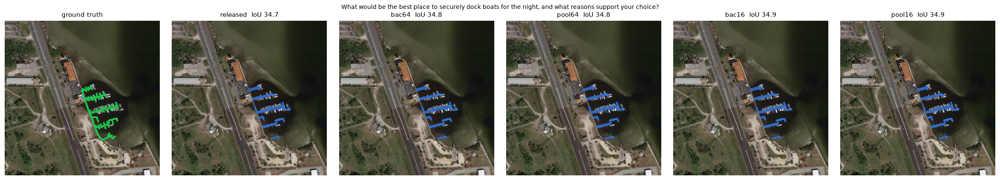

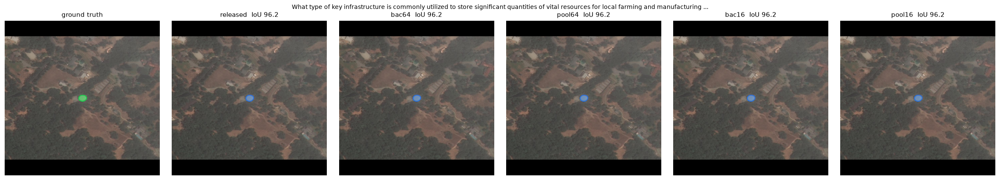

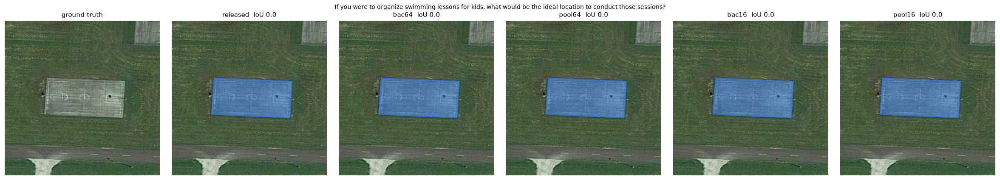

In [ ]:
for ex in EXAMPLES[3:]:
    outs[ex] = show(ex)

## 3b. Delete the image tokens, live
We replace the 64 image tokens with **zeros**, and then with the tokens of a different image (a baseball field). If the masks depended on these tokens, they should fall apart.

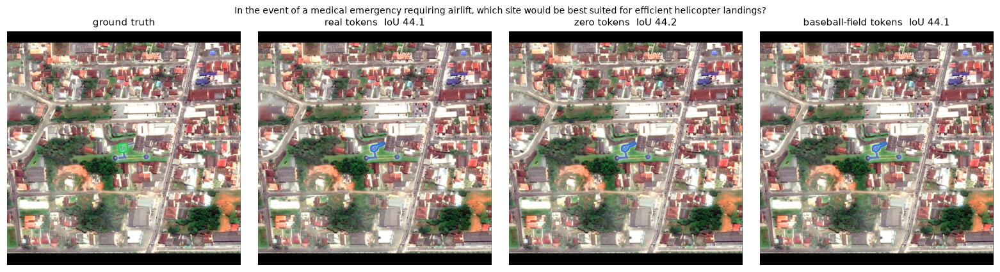

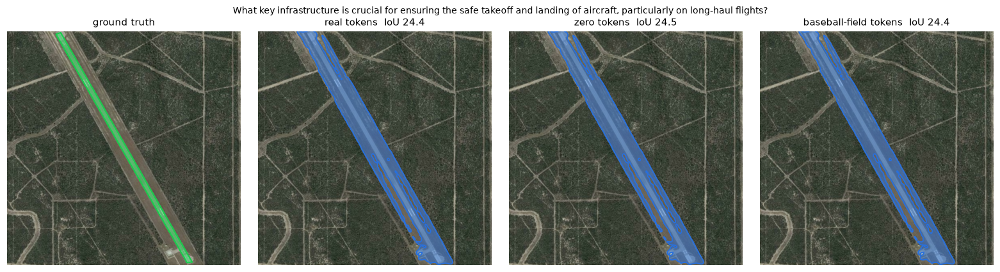

In [ ]:
from evaluate import ZeroTokens

class FixedOtherImage(torch.nn.Module):
    """Feed the LLM the tokens of a different, fixed image."""
    def __init__(self, inner, other):
        super().__init__(); self.inner = inner
        with torch.no_grad():
            self.cache = inner(model.get_vision_tower()(other)[-1])
    def forward(self, x):
        return self.cache

bank.use('released')
other_img = load_example('0634')[0]                                    # a baseball field
other = build_sample(tok, other_img, 'x')['image'][None].to(device)
for ex in ['0305', '0328']:
    img, gt, q, a = load_example(ex)
    res = {}
    bank.use('released');                                      res['real tokens']  = run(model, tok, device, img, q, a, gt)
    model.get_model().mm_projector = ZeroTokens(bank.released); res['zero tokens']  = run(model, tok, device, img, q, a, gt)
    model.get_model().mm_projector = FixedOtherImage(bank.released, other); res['baseball-field tokens'] = run(model, tok, device, img, q, a, gt)
    bank.use('released')
    compare_figure(img, res['real tokens']['gt'], res, q); plt.show()

Across 300 validation images: real tokens **68.40** gIoU, zeroed **68.78**, another image's **68.40**, no tokens **68.22**: the same, within noise. A question about a *different* object gives 64.30: the question matters, the image tokens do not.

**Second dataset (RRSIS-D, 300 images):** zero / another image's / no tokens give 67.63 / 67.63 / 67.70 against 67.63, while a wrong referring sentence drops it to **25.23**.

## 3c. Inside the language model, live
The mask generator reads one vector from the language model: its output for the question. How much does that vector move when we change the image tokens, compared with changing the question? (Over 24 images, the same on both computers: another image's tokens 0.07%, zeroed 8%, none 4%, a different question 134%.)

In [ ]:
from evaluate import NoTokens
cap, orig_seg = {}, model.get_SEG_embedding
def _hook(h, idx, return_all=False):
    out = orig_seg(h, idx, return_all); cap['q'] = out[0][0].detach().float().clone(); return out
model.get_SEG_embedding = _hook
try:
    img, gt, q, a = load_example('0305')
    other_q = load_example('0634')[2]                                       # the baseball-field question
    def state(question=q):
        run(model, tok, device, img, question, a, gt); return cap['q']
    bank.use('released'); s_real = state()
    model.get_model().mm_projector = FixedOtherImage(bank.released, other); s_far = state()
    model.get_model().mm_projector = ZeroTokens(bank.released);            s_zero = state()
    model.get_model().mm_projector = NoTokens(bank.released);              s_none = state()
    bank.use('released');                                                   s_q = state(other_q)
finally:
    model.get_SEG_embedding = orig_seg; bank.use('released')
rel = lambda s: 100 * ((s - s_real).norm() / s_real.norm()).item()
print('question:', q[:90], '...')
for name, s in [("another image's tokens", s_far), ('zeroed tokens', s_zero), ('no image tokens', s_none), ('a different question', s_q)]:
    print(f'{name:>24}: LLM state moves {rel(s):7.2f} %')

question: In the event of a medical emergency requiring airlift, which site would be best suited for ...
  another image's tokens: LLM state moves    0.06 %
           zeroed tokens: LLM state moves   10.29 %
         no image tokens: LLM state moves    2.88 %
    a different question: LLM state moves  162.50 %


## 4. All numbers inside SegEarth-R1 (300 validation images)
Every compressor, at every budget, lands within about one gIoU point of the released model, and no difference is significant (the 95% interval of every change includes zero).

In [ ]:
summ = pd.read_csv(os.path.join(ROOT, 'results', 'summary.csv'))
keep = ['released', 'zero', 'wrong_far', 'none', 'pool64', 'tome64', 'random64', 'uniform64', 'bac64', 'pool16', 'uniform16', 'bac16']
t = summ.set_index('name').loc[keep, ['num_tokens', 'gIoU', 'cIoU', 'dgIoU_vs_released']]
t.style.format({'gIoU': '{:.2%}', 'cIoU': '{:.2%}'}, na_rep='–')

,num_tokens,gIoU,cIoU,dgIoU_vs_released
name,,,,
released,64,68.40%,64.02%,–
zero,64,68.78%,64.39%,"+0.38 [-0.03, +1.08]"
wrong_far,64,68.40%,64.02%,"+0.00 [-0.00, +0.00]"
none,0,68.22%,63.82%,"-0.18 [-0.52, +0.08]"
pool64,64,69.26%,65.51%,"+0.86 [-0.21, +2.16]"
tome64,64,68.80%,64.44%,"+0.39 [-0.27, +1.20]"
random64,64,68.62%,64.25%,"+0.21 [-0.48, +1.05]"
uniform64,64,68.28%,63.84%,"-0.13 [-0.82, +0.71]"
bac64,64,68.26%,63.49%,"-0.15 [-1.13, +0.78]"


## 5. The fair test: when the tokens are the only route to the mask
SegEarth-R1 ignores its tokens, so it cannot judge a compressor. In our fair test the same frozen image features go through a compressor, and a small decoder that also reads the question must draw the mask from the tokens alone. Three seeds per method, the same 300 validation images. (Training all runs took hours on two computers, so we load the saved results.)

,16 tokens,64 tokens
Strided conv (published),44.2,48.3
Average pooling,38.1,44.6
BAC as proposed,33.3,41.4
BAC-v2,42.2,47.6
Supervised BAC (final),45.7,53.4
"same, tokens placed at random",41.2,47.7
"same, all tokens uniform",46.8,50.6


bacq_supb - uniform @16          +1.50  95% CI [0.17, 2.86]
bacq_supb - uniform @64          +5.15  95% CI [4.01, 6.3]
bacq_supbr0 - uniform @64        +2.32  95% CI [1.15, 3.49]
bacq_supb - bacq_supbr0 @64      +2.83  95% CI [1.67, 4.01]


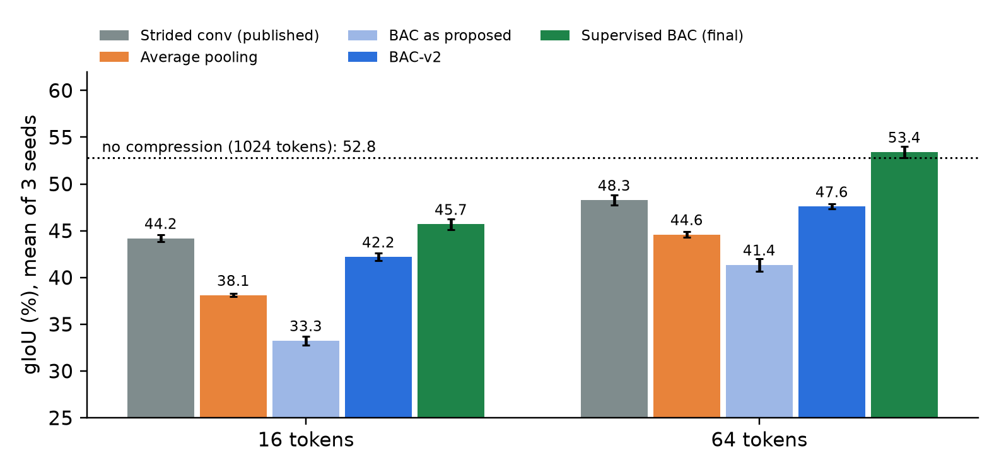

In [ ]:
tb = json.load(open(os.path.join(ROOT, 'exploration', 'results', 'testbed_explore.json')))
S_, C_ = tb['summary'], tb['comparisons']
rows = [('Strided conv (published)', 'uniform'), ('Average pooling', 'pool'), ('BAC as proposed', 'bac'), ('BAC-v2', 'bac2'),
        ('Supervised BAC (final)', 'bacq_supb'), ('  same, tokens placed at random', 'bacq_supbrand'), ('  same, all tokens uniform', 'bacq_supbr0')]
display(pd.DataFrame({'16 tokens': [S_[f'{k}@16']['mean'] for _, k in rows], '64 tokens': [S_[f'{k}@64']['mean'] for _, k in rows]},
                     index=[r for r, _ in rows]).style.format('{:.1f}'))
for k in ['bacq_supb - uniform @16', 'bacq_supb - uniform @64', 'bacq_supbr0 - uniform @64', 'bacq_supb - bacq_supbr0 @64']:
    print(f"{k:32s} {C_[k]['delta']:+.2f}  95% CI {C_[k]['ci']}")
display(Image(os.path.join(ROOT, 'figures', 'final_testbed.png'), width=760))

**Reading it:** BAC as first proposed loses even to plain pooling. Supervised BAC, which learns during training where the true object outlines are, beats the published compressor by **+1.5** at 16 tokens and **+5.2** at 64. The two controls split the 64-token gain: about **+2.3** from the extra training signal and **+2.8** from putting the tokens on the boundaries.

## 6. The real weakness, and our fix (live)
On the official test split SegEarth-R1 misses only 3% of targets of types it was trained on, but 29% of the four types it never saw, and it often returns an **empty mask**. Our fix acts only then:
1. a language model (Qwen2.5-7B) reads **only the question** and names the object type (saved from an earlier run: it does not fit in memory next to SegEarth-R1);
2. OWLv2, an open-vocabulary detector, looks for it in the image (live);
3. if the detector is confident (score ≥ 0.25), SAM draws the mask (live).

SegEarth-R1 returned nothing. Name from the question: 'basketball court'. Detector confidence: 0.81


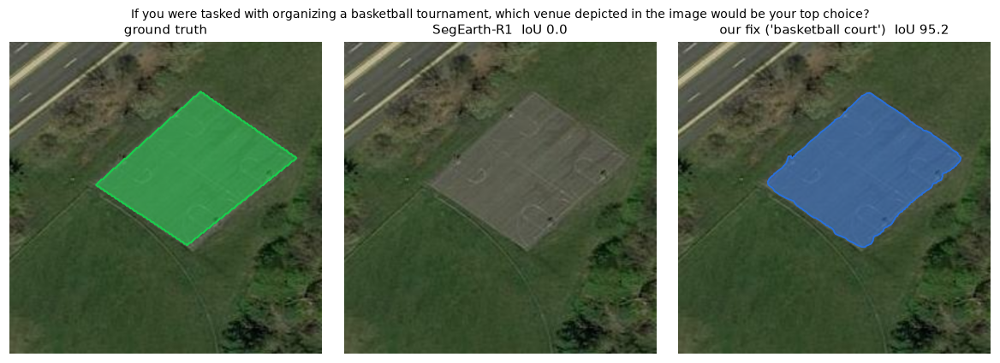

SegEarth-R1 returned nothing. Name from the question: 'lake'. Detector confidence: 0.62


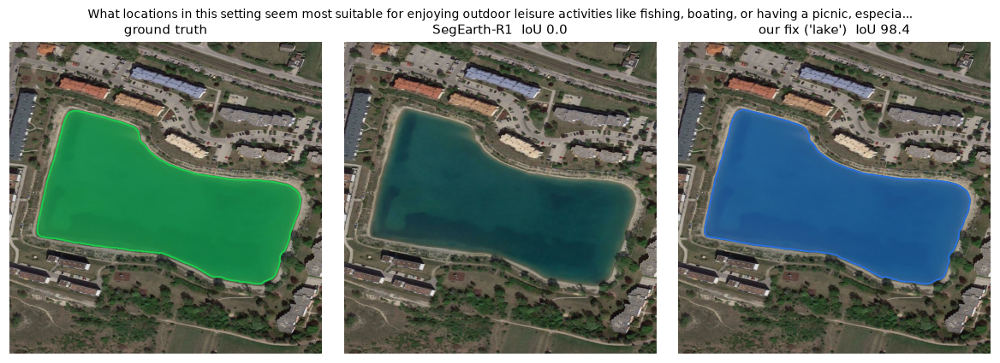

In [ ]:
sys.path.insert(0, os.path.join(ROOT, 'exploration', 'scripts'))
from ov_ceiling import Grounder
grounder = Grounder('base')                                   # OWLv2 (runs on CPU) + SAM ViT-B
names = json.load(open(os.path.join(ROOT, 'exploration', 'results', 'nouns', 'test300_Qwen2.5-7B-Instruct.json')))['predictions']

def with_fix(name):
    img, gt, q, a = load_example(name)
    bank.use('released')
    res = {'SegEarth-R1': run(model, tok, device, img, q, a, gt)}
    if res['SegEarth-R1']['pred'].any():
        print('SegEarth-R1 found something, so the fix is not used.')
    else:
        noun = names[name]['vocab']
        lb = letterbox(img)
        boxes, scores = grounder.boxes(lb, f'a satellite image of a {noun}')
        print(f"SegEarth-R1 returned nothing. Name from the question: '{noun}'. Detector confidence: {scores[0]:.2f}")
        if scores[0] >= 0.25:
            m = grounder.masks(lb, boxes[:1])[0][0]
            g = res['SegEarth-R1']['gt'].astype(bool)
            res[f"our fix ('{noun}')"] = dict(pred=m, iou=(m & g).sum() / max((m | g).sum(), 1))
    compare_figure(img, res['SegEarth-R1']['gt'], res, q); plt.show()

for ex in ['0731', '2627']:          # a basketball court and a lake: types never seen in training
    with_fix(ex)

In [ ]:
p2 = json.load(open(os.path.join(ROOT, 'exploration', 'results', 'p2_results.json')))
for key, s, label in [('valrest|Qwen2.5-7B-Instruct|tau0.25', 'valrest', '535 validation images never used before'),
                      ('testsplit|Qwen2.5-7B-Instruct|tau0.25', 'testsplit', 'official test split (1,928 images)')]:
    r = p2[key]
    base = pd.DataFrame(json.load(open(os.path.join(ROOT, 'exploration', 'results', 'logits', f'{s}_meta.json')))).iou_full.mean() * 100
    print(f"{label:42s} fix used on {r['routed']:3d} images | gIoU {base:.2f} -> {r['gIoU']:.2f} "
          f"({r['d_gIoU'][0]:+.2f}, 95% CI {r['d_gIoU'][1]:+.2f}..{r['d_gIoU'][2]:+.2f}) | cIoU change {r['d_cIoU'][0]:+.2f}")

535 validation images never used before    fix used on  19 images | gIoU 71.20 -> 72.83 (+1.62, 95% CI +0.75..+2.66) | cIoU change +1.16
official test split (1,928 images)         fix used on  49 images | gIoU 70.40 -> 71.40 (+1.00, 95% CI +0.49..+1.53) | cIoU change +0.83


**Reading it:** +1.6 gIoU on images we had never used (significant), +1.0 on the official test split. It is not perfect: when the language model names the wrong type, the fix draws the wrong thing, and it sometimes fills in a mask when the right answer was "nothing".

## 7. Checked on a second computer
Everything inside SegEarth-R1 was re-run from scratch on Kaggle (2× NVIDIA T4 GPUs) with an automatic checker that re-tests every claim on the new results alone.

*Note on the first check below:* it compares our 300 images with the paper's score for **all** validation images, so it is only a rough sanity check. The like-for-like check is the official test split: 70.40 gIoU here vs 70.75 in the paper. (On all 1,135 validation images the released model scores 70.59 vs the paper's 68.60; we could not find the reason.)

In [ ]:
fn = json.load(open(os.path.join(ROOT, 'results', 'final_numbers.json')))
k = fn['kaggle_repro']
print(f"claims passed: {k['claims_pass']}/{k['claims_total']}   configurations within tolerance: {k['configs_pass']}/{k['configs_total']}")
print(f"testbed runs repeated on both machines: largest difference {fn['replication']['max_abs']:.2f} gIoU")
rep = pd.read_csv(os.path.join(ROOT, 'results', 'testbed_replication.csv'))
display(rep.style.format({'mac': '{:.2f}', 'kaggle': '{:.2f}', 'diff': '{:+.2f}'}).hide(axis='index'))
print(open(os.path.join(ROOT, 'results', 'kaggle', 'repro_verification.md')).read().split('## Configuration')[0])

claims passed: 8/8   configurations within tolerance: 30/30
testbed runs repeated on both machines: largest difference 0.43 gIoU


config,tokens,seed,mac,kaggle,diff
bac,16,0,33.70,33.41,-0.28
bac2,16,0,41.74,42.03,+0.29
bac2_randsel,16,0,41.34,41.24,-0.11
pool,16,0,38.23,38.40,+0.17
uniform,16,0,44.61,44.18,-0.43


# Verification against reference results

New results: `../kaggle/outputs/repro_v2/unz/results`  |  Reference: `../kaggle/outputs/repro_v2/ref`

## Claims (checked on the new run alone)

| claim                                                                                       | status   | detail                                          |
|:--------------------------------------------------------------------------------------------|:---------|:------------------------------------------------|
| Released model reproduces the paper (|gIoU - 68.60| <= 1.0)                                 | PASS     | 68.40                                           |
| Zeroing the 64 visual tokens does not lower accuracy (CI upper bound > 0, |delta| < 1)      | PASS     | +0.38 [-0.03, +1.08], r=0.985                   |
| A different-category image's tokens leave the masks unchanged (per-image r >= 0.95)         | PASS     | +0.00, r=1.000                                  |
| No visual tokens at all: a

## 8. Try your own question
Any RGB remote-sensing image plus an implicit question.

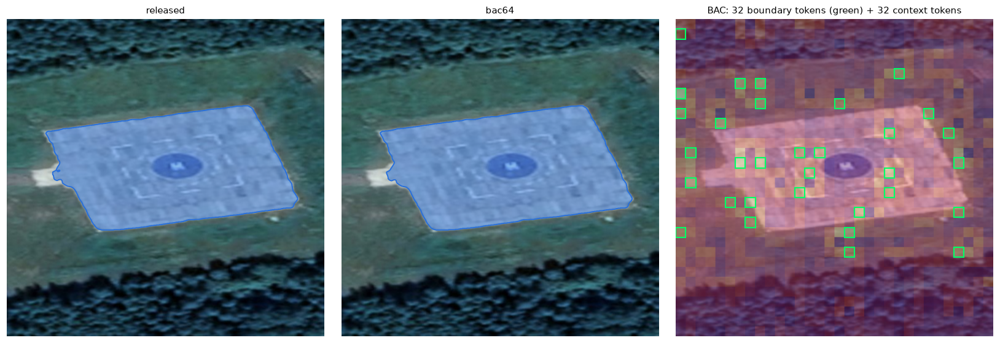

In [ ]:
MY_IMAGE = os.path.join(VAL, 'images', '0121.jpg')          # <- change me
MY_QUESTION = 'Where could a medical helicopter land quickly in this area?'

import cv2
img = cv2.cvtColor(cv2.imread(MY_IMAGE), cv2.COLOR_BGR2RGB)
res = {}
for c in [c for c in ['released', 'bac64'] if c in bank.available()]:
    bank.use(c); res[c] = run(model, tok, device, img, MY_QUESTION)
fig, ax = plt.subplots(1, len(res) + (1 if 'bac64' in res else 0), figsize=(5 * (len(res) + 1), 5))
lb = letterbox(img)
for a_, (c, info) in zip(ax, res.items()):
    overlay(a_, lb, info['pred'], title=c)
if 'bac64' in res:
    draw_bac_allocation(ax[-1], lb, res['bac64'])
plt.tight_layout(); plt.show()

## Takeaways
- **SegEarth-R1 ignores its image tokens.** Zeroed (68.78), another image's (68.40) or no tokens (68.22) give the same masks as the real ones (68.40), on two datasets, and repeated on a second computer. So every compressor ties, and the tokens can even be dropped (32% less language-model work).
- **Where tokens matter, BAC works once trained with true outlines:** +5.2 gIoU over the published compressor at 64 tokens, about half of it from where the tokens are placed.
- **The real weakness is object types never seen in training.** Our fix (name it, find it, draw it) raises gIoU by +1.6 on unused validation images and +1.0 on the official test split.
- **Honest limits:** the language model stayed frozen; the fair test is a small model; the fix only helps when SegEarth-R1 returns nothing.